In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X2, y2 = make_moons(
    n_samples=300,
    noise=0.25,
    random_state=42
)

X2 = StandardScaler().fit_transform(X2)

print("Objects:", len(X2))
print("Classes:", np.bincount(y2))


Objects: 300
Classes: [150 150]


In [2]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

linear = SVC(kernel="linear", C=1)
linear.fit(X2, y2)

accuracy = linear.score(X2, y2)
support_vectors = len(linear.support_vectors_)

print(f"linear: acc={accuracy:.3f} support vectors={support_vectors}")


linear: acc=0.860 support vectors=101


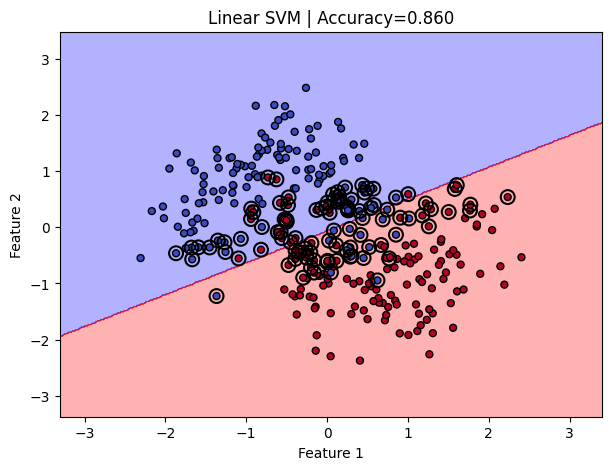

In [3]:

from matplotlib.colors import ListedColormap

def plot_boundary(model, X, y, title, filename=None):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    Z = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    ).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap=ListedColormap(["blue", "red"])
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap="coolwarm",
        s=25,
        edgecolors="black"
    )

    plt.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=100,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5
    )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

    if filename:
        plt.savefig(filename, dpi=150, bbox_inches="tight")

    plt.show()


plot_boundary(
    linear,
    X2,
    y2,
    f"Linear SVM | Accuracy={linear.score(X2, y2):.3f}",
    "svm_linear.png"
)


rbf: acc=0.910 support vectors=92


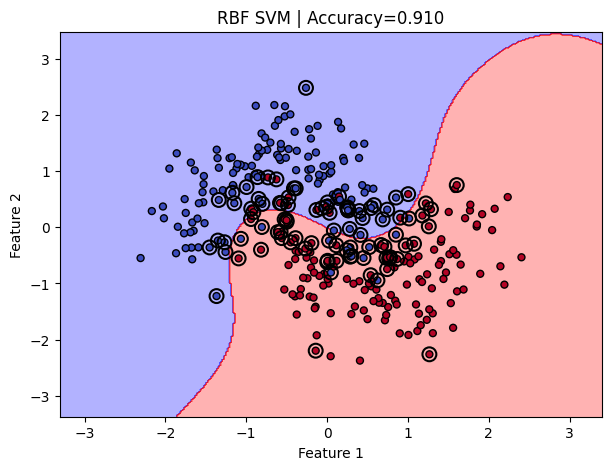

In [4]:

rbf = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

rbf.fit(X2, y2)

print(
    f"rbf: acc={rbf.score(X2, y2):.3f} "
    f"support vectors={len(rbf.support_vectors_)}"
)

plot_boundary(
    rbf,
    X2,
    y2,
    f"RBF SVM | Accuracy={rbf.score(X2, y2):.3f}",
    "svm_rbf.png"
)


C=0.01   acc=0.870 support vectors=300


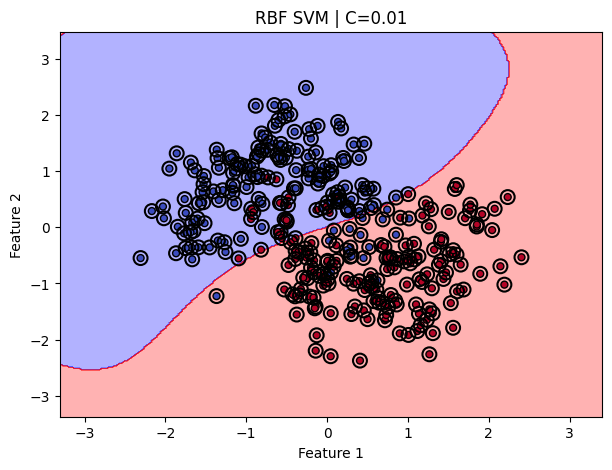

C=1      acc=0.910 support vectors=92


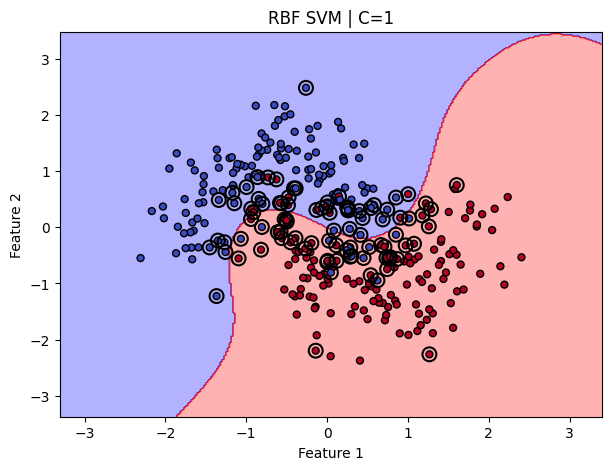

C=100    acc=0.937 support vectors=57


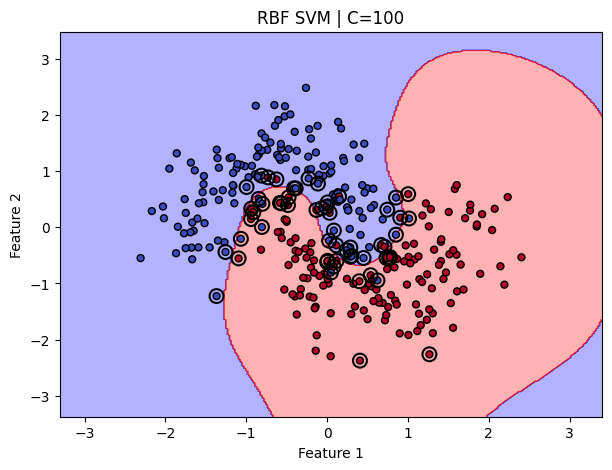

In [5]:

for C in [0.01, 1, 100]:
    model = SVC(
        kernel="rbf",
        C=C,
        gamma="scale"
    )

    model.fit(X2, y2)

    print(
        f"C={C:<6} "
        f"acc={model.score(X2, y2):.3f} "
        f"support vectors={len(model.support_vectors_)}"
    )

    plot_boundary(
        model,
        X2,
        y2,
        f"RBF SVM | C={C}",
        f"svm_rbf_C{C}.png"
    )


In [9]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 3000

df = pd.DataFrame({
    "subscriber_code": [f"SUB{i:05d}" for i in range(n)],
    "region": rng.choice(["North", "South", "East", "West"], n),
    "tariff": rng.choice(["Basic", "Standard", "Premium"], n),
    "age": rng.integers(18, 70, n),
    "monthly_fee": rng.uniform(10, 100, n),
    "tenure_months": rng.integers(1, 73, n),
    "support_calls": rng.poisson(2, n),
    "data_usage": rng.uniform(1, 100, n)
})

logit = (
    -0.4
    + 0.55 * df["support_calls"]
    - 0.025 * df["tenure_months"]
    + 0.008 * df["monthly_fee"]
    - 0.012 * df["data_usage"]
)

prob = 1 / (1 + np.exp(-logit))
df["churn"] = rng.binomial(1, prob)

df.to_csv("0_churn_synthetic.csv", index=False)

print("Dataset created successfully!")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("Churn distribution:")
print(df["churn"].value_counts())


Dataset created successfully!
Rows: 3000
Columns: ['subscriber_code', 'region', 'tariff', 'age', 'monthly_fee', 'tenure_months', 'support_calls', 'data_usage', 'churn']
Churn distribution:
churn
0    1767
1    1233
Name: count, dtype: int64


In [12]:

import time
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

file = Path("0_churn_synthetic.csv")

if not file.exists():
    raise FileNotFoundError(
        "Upload 0_churn_synthetic.csv or run "
        "the dataset-generation cell first."
    )

df = pd.read_csv(file)

X = df.drop(columns=["churn", "subscriber_code"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

prep = ColumnTransformer(
    [
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            ["region", "tariff"]
        )
    ],
    remainder=StandardScaler()
)

svm = make_pipeline(
    prep,
    SVC(kernel="rbf")
)

grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.001, 0.01, 0.1, 1]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    svm,
    grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

t0 = time.perf_counter()
search.fit(X_train, y_train)
elapsed = time.perf_counter() - t0

print("Dataset:", df.shape)
print("Best parameters:", search.best_params_)
print(f"Best ROC-AUC: {search.best_score_:.3f}")
print(f"Training time: {elapsed:.2f} seconds")

table = pd.DataFrame(search.cv_results_).pivot(
    index="param_svc__C",
    columns="param_svc__gamma",
    values="mean_test_score"
)

print("\nGridSearchCV Results:")
print(table.round(3))


Dataset: (3000, 9)
Best parameters: {'svc__C': 0.1, 'svc__gamma': 0.01}
Best ROC-AUC: 0.748
Training time: 32.24 seconds

GridSearchCV Results:
param_svc__gamma  0.001  0.010  0.100  1.000
param_svc__C                                
0.1               0.748  0.748  0.746  0.668
1.0               0.748  0.748  0.732  0.656
10.0              0.747  0.747  0.712  0.615
100.0             0.747  0.735  0.675  0.611


In [14]:


import time
import pandas as pd

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score
from xgboost import XGBClassifier

file = Path("0_churn_synthetic.csv")

if not file.exists():
    raise FileNotFoundError(
        "Dataset missing. Run the dataset-generation "
        "cell or upload the CSV first."
    )

df = pd.read_csv(file)

X = df.drop(columns=["churn", "subscriber_code"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

prep = ColumnTransformer(
    [
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         ["region", "tariff"])
    ],
    remainder=StandardScaler()
)

tree_prep = ColumnTransformer(
    [
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         ["region", "tariff"])
    ],
    remainder="passthrough"
)

if "search" not in globals() or not hasattr(search, "best_params_"):
    raise RuntimeError(
        "Run the successful Task 9.6 GridSearchCV cell first."
    )

best_params = {
    k.replace("svc__", ""): v
    for k, v in search.best_params_.items()
}

models = {
    "SVM RBF (tuned)": make_pipeline(
        prep,
        SVC(kernel="rbf", **best_params)
    ),

    "SVM Linear": make_pipeline(
        prep,
        SVC(kernel="linear", C=1)
    ),

    "Logistic Regression": make_pipeline(
        prep,
        LogisticRegression(max_iter=1000)
    ),

    "Random Forest": make_pipeline(
        tree_prep,
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),

    "XGBoost": make_pipeline(
        tree_prep,
        XGBClassifier(
            n_estimators=127,
            learning_rate=0.05,
            max_depth=3,
            random_state=42,
            eval_metric="logloss"
        )
    )
}

results = []

for name, pipe in models.items():

    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    seconds = time.perf_counter() - t0

    predictions = pipe.predict(X_test)

    if hasattr(pipe, "decision_function"):
        scores = pipe.decision_function(X_test)
    else:
        scores = pipe.predict_proba(X_test)[:, 1]

    f1 = f1_score(y_test, predictions)
    auc = roc_auc_score(y_test, scores)

    results.append({
        "Model": name,
        "F1 Score": round(f1, 3),
        "ROC-AUC": round(auc, 3),
        "Time (seconds)": round(seconds, 3)
    })

results_df = pd.DataFrame(results)

print("TASK 9.7 - MODEL COMPARISON")
print(results_df.to_string(index=False))


TASK 9.7 - MODEL COMPARISON
              Model  F1 Score  ROC-AUC  Time (seconds)
    SVM RBF (tuned)     0.459    0.722           1.441
         SVM Linear     0.593    0.724           0.651
Logistic Regression     0.588    0.724           0.030
      Random Forest     0.537    0.670           1.545
            XGBoost     0.553    0.700           0.299


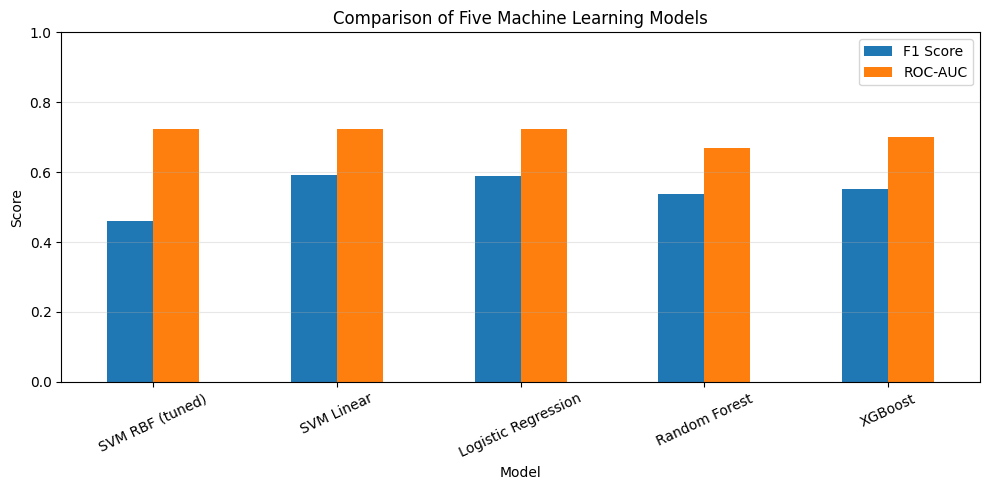

In [15]:

import matplotlib.pyplot as plt

results_df.plot(
    x="Model",
    y=["F1 Score", "ROC-AUC"],
    kind="bar",
    figsize=(10, 5),
    rot=25
)

plt.title("Comparison of Five Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=150)
plt.show()


In [17]:


import time
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler

sizes = [2000, 4000, 8000, 16000, 32000, 64000]

results = []

for n in sizes:
    print(f"\nTesting dataset size: {n}")

    X, y = make_classification(
        n_samples=n,
        n_features=20,
        random_state=42
    )

    X = StandardScaler().fit_transform(X)

    start = time.perf_counter()

    rbf_model = SVC(kernel="rbf")
    rbf_model.fit(X, y)

    rbf_time = time.perf_counter() - start

    start = time.perf_counter()

    linear_model = LinearSVC(
        max_iter=5000,
        random_state=42
    )
    linear_model.fit(X, y)

    linear_time = time.perf_counter() - start

    results.append({
        "Samples": n,
        "RBF SVM Time": rbf_time,
        "LinearSVC Time": linear_time
    })

    print(f"RBF SVM: {rbf_time:.3f} seconds")
    print(f"LinearSVC: {linear_time:.3f} seconds")

results_df = pd.DataFrame(results)

print("\nFINAL SCALABILITY RESULTS")
print(results_df.to_string(index=False))



Testing dataset size: 2000
RBF SVM: 0.081 seconds
LinearSVC: 0.004 seconds

Testing dataset size: 4000
RBF SVM: 0.217 seconds
LinearSVC: 0.007 seconds

Testing dataset size: 8000
RBF SVM: 1.485 seconds
LinearSVC: 0.013 seconds

Testing dataset size: 16000
RBF SVM: 2.988 seconds
LinearSVC: 0.024 seconds

Testing dataset size: 32000
RBF SVM: 9.126 seconds
LinearSVC: 0.048 seconds

Testing dataset size: 64000
RBF SVM: 80.944 seconds
LinearSVC: 0.094 seconds

FINAL SCALABILITY RESULTS
 Samples  RBF SVM Time  LinearSVC Time
    2000      0.081126        0.003599
    4000      0.217419        0.007095
    8000      1.484924        0.013315
   16000      2.988355        0.024083
   32000      9.125751        0.048165
   64000     80.944227        0.093920


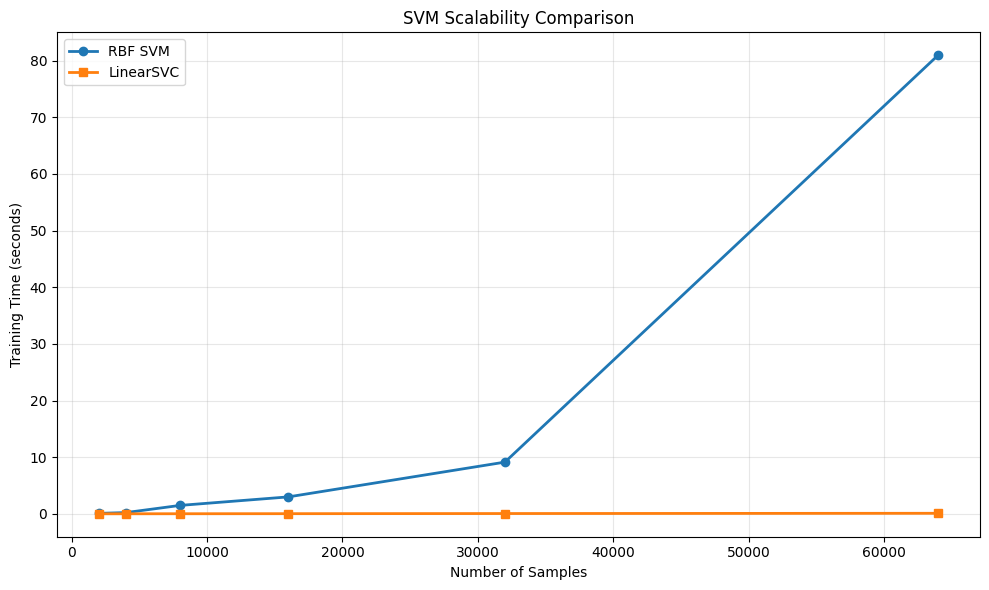

In [18]:


plt.figure(figsize=(10, 6))

plt.plot(
    results_df["Samples"],
    results_df["RBF SVM Time"],
    marker="o",
    linewidth=2,
    label="RBF SVM"
)

plt.plot(
    results_df["Samples"],
    results_df["LinearSVC Time"],
    marker="s",
    linewidth=2,
    label="LinearSVC"
)

plt.xlabel("Number of Samples")
plt.ylabel("Training Time (seconds)")
plt.title("SVM Scalability Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("svm_scalability.png", dpi=150)
plt.show()
